# Fashion

Выбираем **4000 фото** для сегментации: футболки и топы (`1`), брюки (`6`), платья (`10`). [Датасет на Kaggle](https://www.kaggle.com/competitions/imaterialist-fashion-2020-fgvc7/data).

Одна строка CSV — один объект. На фото может быть несколько классов. Пока анализируем только аннотации.


## Библиотеки

Проверяем зависимости из `pyproject.toml` и устанавливаем недостающие. Нужен Python 3.11+.


In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Откройте ноутбук внутри папки проекта.')

!"{sys.executable}" "{ROOT}/scripts/install_dependencies.py"


Все зависимости уже установлены в подходящих версиях.


In [12]:
from pathlib import Path
import json
import random

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAW = ROOT / 'data/raw/imaterialist'
PROCESSED = ROOT / 'data/processed'
FIGURES = ROOT / 'reports/figures/fashion'
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
CLASS_IDS = [1, 6, 10]
SAMPLE_SIZE = 4000
SEED = 42
pd.set_option('display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': False})


## Загрузка данных

Скачиваем готовый набор с Hugging Face, если файлов ещё нет. Архив занимает около 1,73 ГиБ.


In [3]:
!"{sys.executable}" "{ROOT}/scripts/download_data.py" fashion


Фотографии и аннотации уже скачаны.
Готово фотографий: 4000


## Исходные данные

Считаем фото и объекты. Проверяем классы и размеры из CSV.


In [14]:
labels = json.loads((RAW / 'label_descriptions.json').read_text())
categories = pd.DataFrame(labels['categories']).set_index('id')
SOURCE_CSV = RAW / 'train.csv'
if not SOURCE_CSV.is_file():
    SOURCE_CSV = PROCESSED / 'selected_annotations.csv'
data_label = 'Полный исходный набор' if SOURCE_CSV == RAW / 'train.csv' else 'Выборка Hugging Face'
print('Источник анализа:', data_label)
metadata = pd.read_csv(
    SOURCE_CSV,
    usecols=['ImageId', 'ClassId', 'Height', 'Width'],
    dtype={'ImageId': 'string', 'ClassId': 'int64', 'Height': 'int64', 'Width': 'int64'},
)
if not metadata['ClassId'].isin(categories.index).all():
    raise ValueError('Найдены неизвестные классы.')
if (metadata[['Width', 'Height']] <= 0).any().any():
    raise ValueError('Найдены некорректные размеры.')
if (metadata.groupby('ImageId')[['Width', 'Height']].nunique() > 1).any().any():
    raise ValueError('Для одного фото указаны разные размеры.')

counts = categories[['name', 'supercategory']].join(
    metadata.groupby('ClassId').agg(images=('ImageId', 'nunique'), objects=('ImageId', 'size'))
).fillna({'images': 0, 'objects': 0}).astype(
    {'images': int, 'objects': int}
).sort_values('images', ascending=False)

display(pd.DataFrame({
    'Показатель': ['Уникальные фотографии', 'Объекты / маски', 'Категории'],
    'Количество': [metadata['ImageId'].nunique(), len(metadata), len(categories)],
}))
display(counts.rename_axis('ClassId'))


Источник анализа: Полный исходный набор


,Показатель,Количество
0,Уникальные фотографии,45623
1,Объекты / маски,333401
2,Категории,46


,name,supercategory,images,objects
ClassId,,,,
33,neckline,garment parts,33160,34258
31,sleeve,garment parts,29465,59448
23,shoe,legs and feet,23954,46374
10,dress,wholebody,18666,18739
1,"top, t-shirt, sweatshirt",upperbody,16176,16548
32,pocket,garment parts,13174,27179
6,pants,lowerbody,12347,12414
28,collar,garment parts,9801,10159
4,jacket,upperbody,7742,7833


## Частоты классов

Сравниваем целые предметы одежды и аксессуары. Детали и декор исключаем из этого сравнения.


,name,supercategory,images,objects
id,,,,
23,shoe,legs and feet,23954,46374
10,dress,wholebody,18666,18739
1,"top, t-shirt, sweatshirt",upperbody,16176,16548
6,pants,lowerbody,12347,12414
4,jacket,upperbody,7742,7833
24,"bag, wallet",others,6907,7217
19,belt,waist,6667,6851
0,"shirt, blouse",upperbody,6115,6161
8,skirt,lowerbody,5034,5046


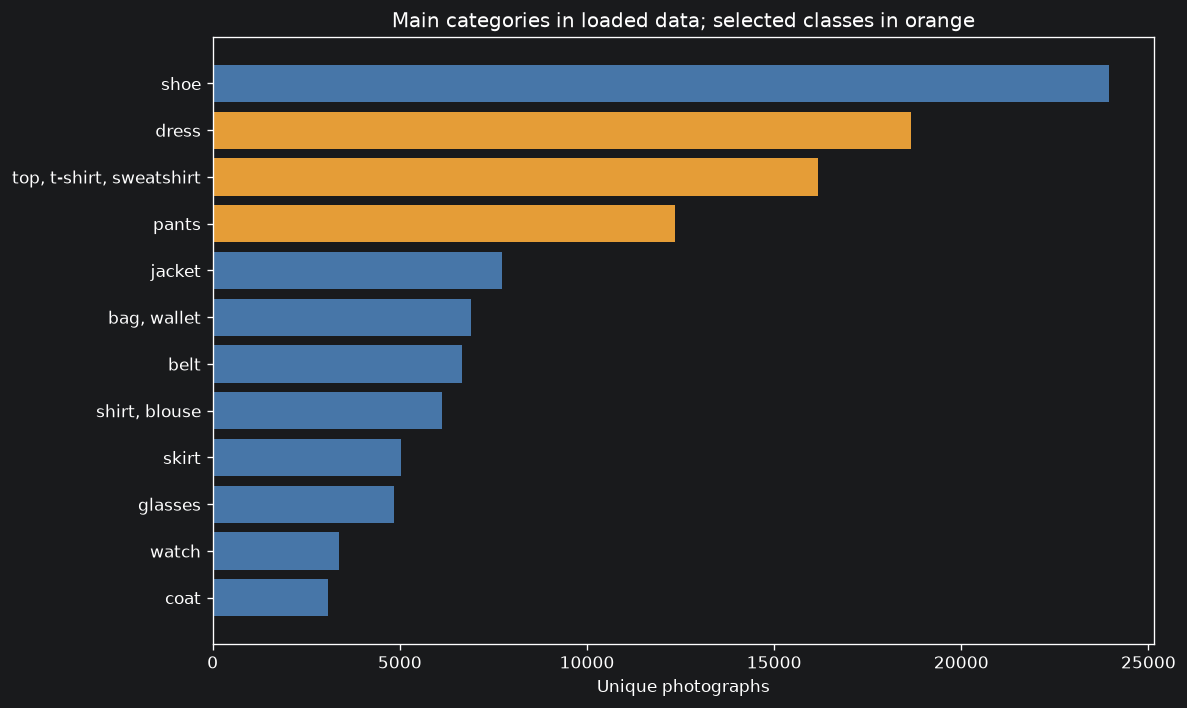

In [15]:
parts = {'garment parts', 'closures', 'decorations'}
main_counts = counts[(~counts['supercategory'].isin(parts)) & (counts['images'] > 0)]
display(main_counts.head(12))

fig, ax = plt.subplots(figsize=(10, 6))
top = main_counts.head(12).iloc[::-1]
colors = ['#e59d37' if cid in CLASS_IDS else '#4776a8' for cid in top.index]
ax.barh(top['name'], top['images'], color=colors)
ax.set_xlabel('Unique photographs')
ax.set_title('Main categories in loaded data; selected classes in orange')
fig.tight_layout()
fig.savefig(FIGURES / 'main_class_counts.png', bbox_inches='tight')
plt.show()


## Выборка

Выбираем 4000 фото, пополняя наименее представленный класс. Учитываем все выбранные классы на каждом фото. Фиксируем `seed=42`.

Сохраняем список фото и их маски. Такой отбор выравнивает частоты классов и меняет исходные пропорции.


In [16]:
class_ids = sorted(set(CLASS_IDS))
if not class_ids or not set(class_ids).issubset(categories.index):
    raise ValueError('Выберите существующие классы.')
candidates = metadata[metadata['ClassId'].isin(class_ids)]
labels_by_image = candidates.groupby('ImageId')['ClassId'].agg(set).to_dict()
if not 0 < SAMPLE_SIZE <= len(labels_by_image):
    raise ValueError('Недостаточно фотографий для выборки.')

rng = random.Random(SEED)
pools = {
    cid: sorted(iid for iid, labels in labels_by_image.items() if cid in labels)
    for cid in class_ids
}
for pool in pools.values():
    rng.shuffle(pool)
chosen = set()
frequency = dict.fromkeys(class_ids, 0)

# Пополняем наименее представленный класс.
while len(chosen) < SAMPLE_SIZE:
    for pool in pools.values():
        while pool and pool[-1] in chosen:
            pool.pop()
    available_classes = [cid for cid in class_ids if pools[cid]]
    if not available_classes:
        raise ValueError('Закончились доступные фотографии.')
    minimum = min(frequency[cid] for cid in available_classes)
    cid = rng.choice([cid for cid in available_classes if frequency[cid] == minimum])
    iid = pools[cid].pop()
    chosen.add(iid)
    for label in labels_by_image[iid]:
        frequency[label] += 1

selected_metadata = candidates[candidates['ImageId'].isin(chosen)]
manifest = pd.DataFrame([
    {
        'ImageId': iid,
        'file_name': f'train/{iid}.jpg',
        'ClassIds': ' '.join(map(str, sorted(group['ClassId'].unique()))),
        'Width': int(group['Width'].iloc[0]),
        'Height': int(group['Height'].iloc[0]),
        'objects': len(group),
    }
    for iid, group in selected_metadata.groupby('ImageId', sort=True)
])
manifest.to_csv(PROCESSED / 'image_manifest.csv', index=False)
selected_counts = categories.loc[class_ids, ['name', 'supercategory']].join(
    selected_metadata.groupby('ClassId').agg(
        images=('ImageId', 'nunique'), objects=('ImageId', 'size')
    )
).sort_values('images', ascending=False)
summary = {
    'original_images': int(metadata['ImageId'].nunique()),
    'original_objects': len(metadata),
    'candidate_images': len(labels_by_image),
    'candidate_objects': len(candidates),
    'selected_images': len(manifest),
    'selected_objects': len(selected_metadata),
}
assert len(manifest) == SAMPLE_SIZE and manifest['ImageId'].is_unique
assert set(selected_metadata['ClassId']) == set(class_ids)

display(pd.DataFrame({
    'Этап': [data_label, 'Снимки выбранных классов', 'Итоговая выборка'],
    'Фотографии': [summary['original_images'], summary['candidate_images'], summary['selected_images']],
    'Объекты': [summary['original_objects'], summary['candidate_objects'], summary['selected_objects']],
}))
comparison = counts.loc[CLASS_IDS, ['name', 'images', 'objects']].rename(
    columns={'images': 'source_images', 'objects': 'source_objects'}
).join(selected_counts[['images', 'objects']].rename(
    columns={'images': 'selected_images', 'objects': 'selected_objects'}
))
display(comparison)
print('Разница частот:', selected_counts['images'].max() - selected_counts['images'].min())


,Этап,Фотографии,Объекты
0,Полный исходный набор,45623,333401
1,Снимки выбранных классов,39658,47701
2,Итоговая выборка,4000,5295


,name,source_images,source_objects,selected_images,selected_objects
id,,,,,
1,"top, t-shirt, sweatshirt",16176,16548,1748,1789
6,pants,12347,12414,1748,1753
10,dress,18666,18739,1747,1753


Разница частот: 1


In [17]:
# Читаем большие строки масок порциями.
annotation_path = PROCESSED / 'selected_annotations.csv'
temporary_path = annotation_path.with_suffix('.csv.tmp')
first = True
missing_attributes = 0
saved_objects = 0
for chunk in pd.read_csv(SOURCE_CSV, chunksize=10_000, keep_default_na=False):
    missing_attributes += int(chunk['AttributesIds'].eq('').sum())
    selected_chunk = chunk[chunk['ImageId'].isin(chosen) & chunk['ClassId'].isin(class_ids)]
    if selected_chunk.empty:
        continue
    selected_chunk.to_csv(temporary_path, mode='w' if first else 'a', header=first, index=False)
    saved_objects += len(selected_chunk)
    first = False
if first or saved_objects != summary['selected_objects']:
    temporary_path.unlink(missing_ok=True)
    raise ValueError('Не удалось сохранить все выбранные маски.')
temporary_path.replace(annotation_path)
summary['annotations_without_attributes'] = missing_attributes
print('Сохранено масок:', saved_objects)


Сохранено масок: 5295


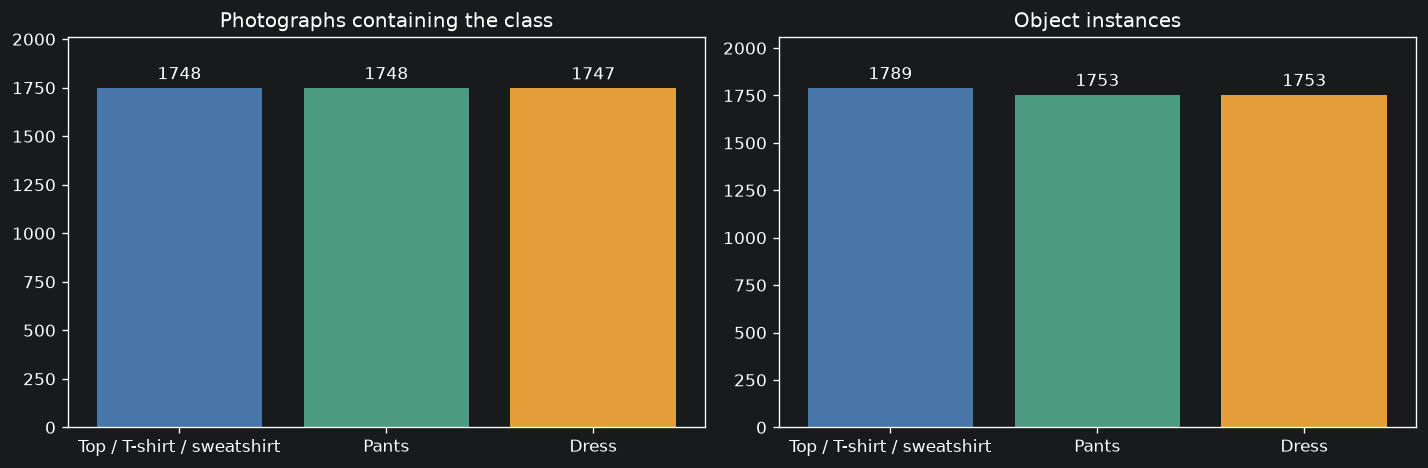

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = ['Top / T-shirt / sweatshirt', 'Pants', 'Dress']
selected_counts = selected_counts.loc[CLASS_IDS]
for ax, column, title in zip(axes, ['images', 'objects'],
                            ['Photographs containing the class', 'Object instances']):
    values = selected_counts[column].to_list()
    bars = ax.bar(names, values, color=['#4776a8', '#4b9b80', '#e59d37'])
    ax.bar_label(bars, padding=3)
    ax.set_ylim(0, max(values) * 1.15)
    ax.set_title(title)
fig.tight_layout()
fig.savefig(FIGURES / 'selected_class_balance.png', bbox_inches='tight')
plt.show()


## Классы на одном фото

Считаем, сколько фото содержат оба класса. На диагонали — число фото с каждым классом.


In [19]:
presence = pd.crosstab(selected_metadata['ImageId'], selected_metadata['ClassId']).clip(upper=1)
presence = presence.reindex(columns=CLASS_IDS, fill_value=0)
cooccurrence = presence.T @ presence
cooccurrence.index = names
cooccurrence.columns = names
display(cooccurrence)
combinations = presence.apply(lambda row: ' + '.join(
    str(cid) for cid in CLASS_IDS if row[cid]), axis=1).value_counts()
display(combinations.rename('photographs').to_frame())
print('Сумма частот классов:', int(presence.to_numpy().sum()))
print('Уникальных фотографий:', len(presence))


,Top / T-shirt / sweatshirt,Pants,Dress
Top / T-shirt / sweatshirt,1748,1109,39
Pants,1109,1748,101
Dress,39,101,1747


,photographs
10,1613
1 + 6,1103
1,606
6,544
6 + 10,95
1 + 10,33
1 + 6 + 10,6


Сумма частот классов: 5243
Уникальных фотографий: 4000


## Размеры фото

Смотрим размеры фотографий из аннотаций.


,Width,Height,aspect_ratio
count,4000.00,4000.00,4000.00
mean,1705.49,2195.07,0.78
std,1366.90,1520.90,0.27
min,151.00,341.00,0.23
25%,683.00,1024.00,0.67
50%,1092.50,1500.00,0.67
75%,2231.25,3000.00,0.75
max,8688.00,8380.00,2.09


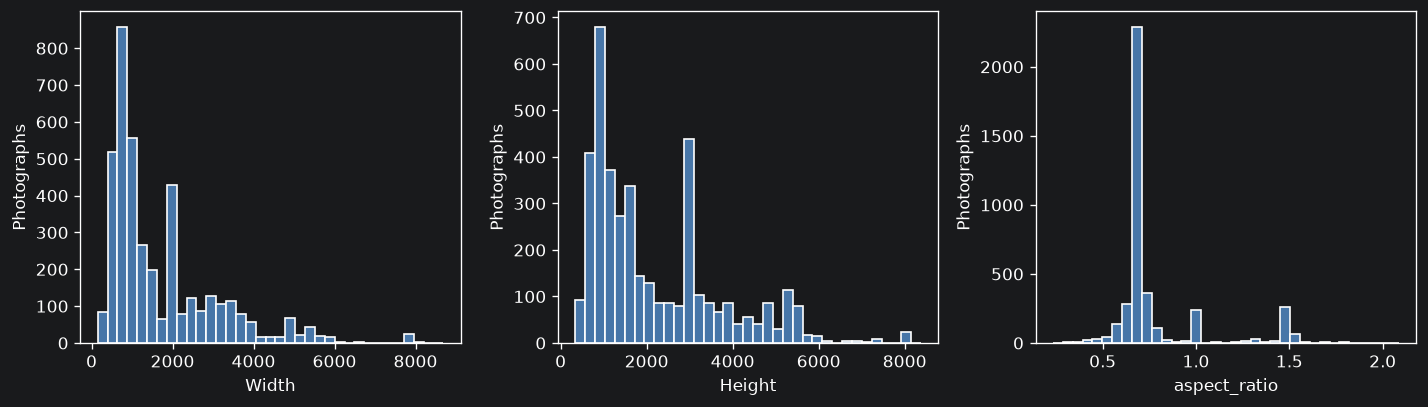

In [20]:
image_sizes = manifest[['Width', 'Height']].copy()
image_sizes['aspect_ratio'] = image_sizes['Width'] / image_sizes['Height']
display(image_sizes.describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(axes, ['Width', 'Height', 'aspect_ratio']):
    ax.hist(image_sizes[column], bins=35, color='#4776a8', edgecolor='white')
    ax.set_xlabel(column)
    ax.set_ylabel('Photographs')
fig.tight_layout()
fig.savefig(FIGURES / 'image_sizes.png', bbox_inches='tight')
plt.show()


## Фотографии

Фото и аннотации загружаются в начале ноутбука. Здесь проверяем наличие файлов.


In [21]:
local_files = manifest['file_name'].map(lambda name: RAW / name)
available = local_files.map(lambda path: path.is_file() and path.stat().st_size > 0)
print(f'Фотографий на диске: {int(available.sum())} из {len(manifest)}')
print(f'Доля выбранных фотографий от исходного train: {len(manifest) / summary["original_images"]:.1%}')
print('Без атрибутов в загруженных аннотациях:', summary['annotations_without_attributes'])
print('Отсутствие атрибутов само по себе не исключает пример из задачи сегментации без атрибутов.')
display(manifest.head())


Фотографий на диске: 4000 из 4000
Доля выбранных фотографий от исходного train: 8.8%
Без атрибутов в загруженных аннотациях: 126991
Отсутствие атрибутов само по себе не исключает пример из задачи сегментации без атрибутов.


,ImageId,file_name,ClassIds,Width,Height,objects
0,0004467156e47b0eb6de4aa6479cbd15,train/0004467156e47b0eb6de4aa6479cbd15.jpg,10,500,750,1
1,000b3a87508b0fa185fbd53ecbe2e4c6,train/000b3a87508b0fa185fbd53ecbe2e4c6.jpg,10,852,1280,1
2,000e973c99dc090afd7898c93daf0dbc,train/000e973c99dc090afd7898c93daf0dbc.jpg,6 10,3264,4928,2
3,001657dc6f979869ebf38ea741e90675,train/001657dc6f979869ebf38ea741e90675.jpg,1,1141,1998,1
4,0017af9f7fa8ce9e7558bb924cec324e,train/0017af9f7fa8ce9e7558bb924cec324e.jpg,1 6,607,1797,2


## Итог

- Выбрано 4000 фото и 5295 масок.
- Классы встречаются на 1748, 1748 и 1747 фото. На одном снимке может быть несколько классов.
- Далее: проверить дубликаты и маски, зафиксировать разбиения.
- Новые данные для ручного обогащения собираем отдельно.

При изменении параметров используйте пересчитанные значения в таблицах выше.
